# 1 · Gold and silver: why the PCA pullback fails

**Question:** gold and silver move together. After PCA removes what they share with each other and with the US dollar, does the leftover (silver vs gold) *pull back* to normal, so it could be traded?

**Data:** Vantage MT5 hourly prices 2019 – 2026 for XAUUSD, XAGUSD and the US dollar index; HistData daily gold/silver ratio 2010 – 2026.

**Steps**
1. PCA on the standardised hourly returns of gold, silver and the dollar index: how much each factor explains and what it is made of.
2. **Variance ratio** of the out-of-sample silver-vs-gold leftover. VR = variance of k-day moves ÷ (k × variance of 1-day moves). Below 1 = pulls back, about 1 = random walk, above 1 = trends.
3. The gold/silver ratio itself over 16 years.
4. For reference, the result of trading that leftover (full details in `backtesting/01`).

In [1]:
import sys
sys.path.insert(0, "../src")   # shared code lives in src/; data in ../data (see README)
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)

Data: Vantage MT5 hourly, 2019-01-01 -> 2026-09-29, 45,421 bars

1. PCA on gold, silver, USD index (hourly, full sample)
variance explained %:  PC1 68%  PC2 24%  PC3 8%
loadings:
            PC1   PC2   PC3
gold       0.63  0.28  0.72
silver     0.62  0.36 -0.69
USD index -0.46  0.89  0.05
   PC1 = all three together (metals priced in dollars), PC2 = the dollar on its own, PC3 = silver vs gold (the only thing left to trade)
correlations:
       xau   xag  usdx
xau   1.00  0.77 -0.40
xag   0.77  1.00 -0.35
usdx -0.40 -0.35  1.00



2. Variance ratio of the silver-vs-gold leftover (out-of-sample).  <1 comes back,  >=1 drifts/trends
   1 day: 1.01  5 days: 1.04  10 days: 1.20  20 days: 1.48



3. Gold/silver ratio by year (HistData daily):
          first   min    max  last
time_utc                          
2010       65.0  46.0   70.9  46.1
2011       46.0  31.7   57.5  56.2
2012       55.8  48.4   59.0  55.2
2013       55.3  52.3   67.2  62.0
2014       61.8  60.5   78.0  75.4
2015       75.0  69.2   79.5  76.7
2016       76.5  65.7   83.3  72.4
2017       72.0  67.8   79.3  77.0
2018       76.8  75.8   86.1  83.0
2019       82.9  79.3   93.4  85.1
2020       84.9  69.5  122.2  72.0
2021       71.3  64.2   80.8  78.5
2022       78.5  75.3   95.4  76.1
2023       75.9  75.9   91.3  86.7
2024       86.7  73.0   91.8  90.8
2025       90.6  55.3  105.0  60.4
2026       59.8  45.9   73.8  73.3
   typical distance from its own 1-year average: 5.2% (median), 18.2% (90th pct)



4. Residual strategy backtest (pca_strategy.py, costs included):
       trades  win_pct  return %
entry                           
2019        9     55.6      -0.2
2020       17     41.2      -5.3
2021       16     56.2       1.5
2022       22     68.2      -0.2
2023        9     33.3      -3.8
2024       10     60.0      -0.3
2025       12     50.0      -5.0
2026        9     44.4      -4.1
   total 104 trades, Sharpe -0.61, 7 of 8 years negative



charts in G:\pca-forex-analysis\data\gold_silver


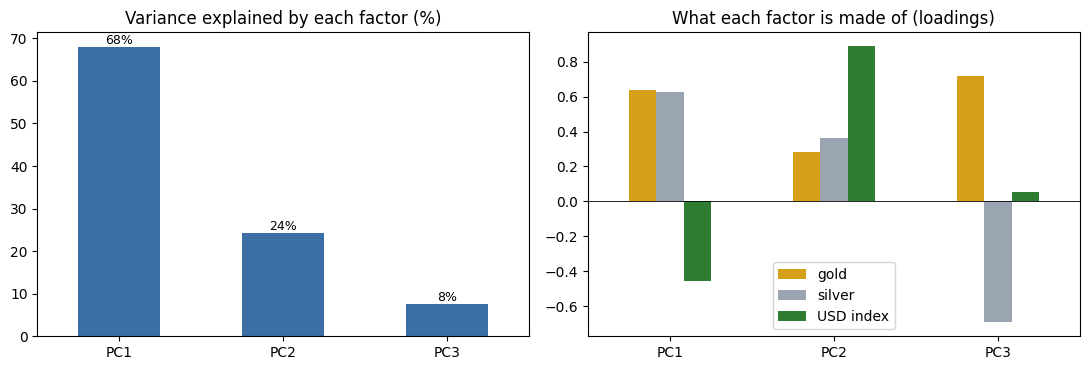

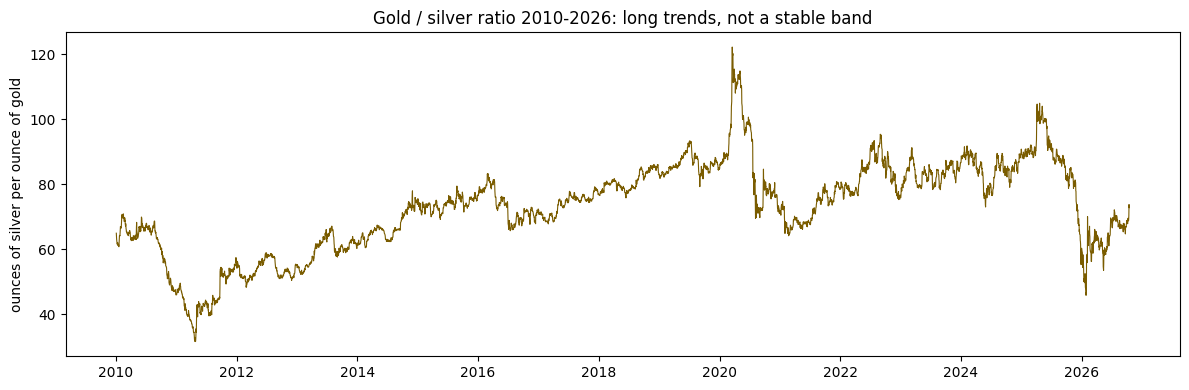

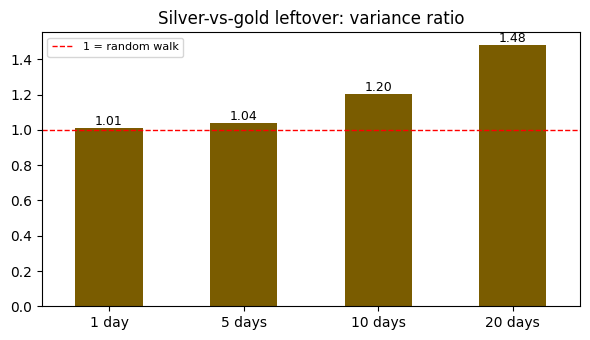

<Figure size 640x480 with 0 Axes>

In [2]:
%run ../src/gold_silver_analysis.py

### What this shows
* **PC1 68%**: gold, silver and the dollar move together (metals rise when the dollar falls). **PC2 24%**: the dollar on its own. **PC3 only 8%**: silver vs gold, the only leftover there is to trade.
* The leftover does **not** pull back: the variance ratio is about 1 at short horizons and **rises to 1.20 at 10 days and 1.48 at 20 days**, so it trends.
* The ratio moved from 32 to 122 and from 105 to 46 within a year: long trends, not a stable band.
* Trading it: 104 trades, Sharpe −0.61, 7 of 8 years negative.

**Conclusion:** PCA confirms gold and silver are strongly linked, but their *difference* trends, so there is no pullback to trade.